# Initial Analysis

Goal: understand the data (columns, data types, missing values, duplicates).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('../data/raw/DataCoSupplyChainDataset.csv', encoding='cp1252')

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  str    
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  str    
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  str    
 9   Customer City                  180519 non-null  str    
 10  Customer Country               180519 non-null  str    
 11  Customer Email                 180519 non-null  str    
 12  Customer Fname                 180519 non

## Duplicate Cells

In [3]:
df.duplicated().sum()

np.int64(0)

## Confirm Identical Columns

Same values in every row.

In [4]:
df['Benefit per order'].equals(df['Order Profit Per Order'])

True

In [5]:
df['Sales per customer'].equals(df['Order Item Total'])

True

In [6]:
df['Category Id'].equals(df['Product Category Id'])

True

In [7]:
print(df['Customer Email'].equals(df['Customer Password']))

df[['Customer Email', 'Customer Password']].head()

True


,Customer Email,Customer Password
0,XXXXXXXXX,XXXXXXXXX
1,XXXXXXXXX,XXXXXXXXX
2,XXXXXXXXX,XXXXXXXXX
3,XXXXXXXXX,XXXXXXXXX
4,XXXXXXXXX,XXXXXXXXX


In [8]:
df['Customer Id'].equals(df['Order Customer Id'])

True

In [9]:
df['Order Item Cardprod Id'].equals(df['Product Card Id'])

True

In [10]:
df['Order Item Product Price'].equals(df['Product Price'])

True

Since they are identical, I will keep the columns with more clear names:
- Order Profit Per Order
- Order Item Total
- Product Category Id
- Order Customer Id
- Product Card Id
- Product Price

Both *Customer Email* and *Customer Password* can be dropped, since all their values are 'XXXXXXXXX'

## 1:1 Mappings

Each value of one column matches exactly one value of the other, e.g. an ID and its name.

In [11]:
df.groupby('Shipping Mode')['Days for shipment (scheduled)'].unique()

Shipping Mode
First Class       [1]
Same Day          [0]
Second Class      [2]
Standard Class    [4]
Name: Days for shipment (scheduled), dtype: object

Both columns are useful for this analysis, therefore neither will be dropped.

In [12]:
df.groupby('Department Name')['Department Id'].unique()

Department Name
Apparel                [4]
Book Shop              [8]
Discs Shop             [9]
Fan Shop               [7]
Fitness                [2]
Footwear               [3]
Golf                   [5]
Health and Beauty     [12]
Outdoors               [6]
Pet Shop              [11]
Technology            [10]
Name: Department Id, dtype: object

Both columns are useful for this analysis, therefore neither will be dropped.

In [13]:
df.groupby('Product Image')['Order Item Cardprod Id'].unique()

Product Image
http://images.acmesports.sports/Adult+dog+supplies                                           [1359]
http://images.acmesports.sports/Baby+sweater                                                 [1347]
http://images.acmesports.sports/Bag+Boy+Beverage+Holder                                       [778]
http://images.acmesports.sports/Bag+Boy+M330+Push+Cart                                        [777]
http://images.acmesports.sports/Bowflex+SelectTech+1090+Dumbbells                             [226]
                                                                                              ...  
http://images.acmesports.sports/adidas+Kids%27+F5+Messi+FG+Soccer+Cleat                        [37]
http://images.acmesports.sports/adidas+Men%27s+F10+Messi+TRX+FG+Soccer+Cleat                   [44]
http://images.acmesports.sports/adidas+Men%27s+Germany+Black+Crest+Away+Tee                   [567]
http://images.acmesports.sports/adidas+Youth+Germany+Black%2FRed+Away+Match+Soccer+Jer

In [14]:
df.groupby('Product Name')['Order Item Cardprod Id'].unique()

Product Name
Adult dog supplies                               [1359]
Baby sweater                                     [1347]
Bag Boy Beverage Holder                           [778]
Bag Boy M330 Push Cart                            [777]
Bowflex SelectTech 1090 Dumbbells                 [226]
                                                  ...  
adidas Kids' F5 Messi FG Soccer Cleat              [37]
adidas Men's F10 Messi TRX FG Soccer Cleat         [44]
adidas Men's Germany Black Crest Away Tee         [567]
adidas Youth Germany Black/Red Away Match Soc     [565]
insta-bed Neverflat Air Mattress                  [982]
Name: Order Item Cardprod Id, Length: 118, dtype: object

In [15]:
df.groupby('Product Name')['Product Image'].unique()

Product Name
Adult dog supplies                               [http://images.acmesports.sports/Adult+dog+sup...
Baby sweater                                        [http://images.acmesports.sports/Baby+sweater]
Bag Boy Beverage Holder                          [http://images.acmesports.sports/Bag+Boy+Bever...
Bag Boy M330 Push Cart                           [http://images.acmesports.sports/Bag+Boy+M330+...
Bowflex SelectTech 1090 Dumbbells                [http://images.acmesports.sports/Bowflex+Selec...
                                                                       ...                        
adidas Kids' F5 Messi FG Soccer Cleat            [http://images.acmesports.sports/adidas+Kids%2...
adidas Men's F10 Messi TRX FG Soccer Cleat       [http://images.acmesports.sports/adidas+Men%27...
adidas Men's Germany Black Crest Away Tee        [http://images.acmesports.sports/adidas+Men%27...
adidas Youth Germany Black/Red Away Match Soc    [http://images.acmesports.sports/adidas+Youth+.

Both *Product Image* and *Order Item Cardprod Id* can be dropped.

## Empty Columns

There is only one completely empty column - *Product Description* - and it can be safely dropped.

In [16]:
df['Product Description'].isna().sum()

np.int64(180519)

## Constant Columns

In [17]:
df['Customer Email'].unique()

<StringArray>
['XXXXXXXXX']
Length: 1, dtype: str

In [18]:
df['Customer Password'].unique()

<StringArray>
['XXXXXXXXX']
Length: 1, dtype: str

In [19]:
df['Product Status'].unique()

array([0])

All three of these columns can be dropped.

## Mostly missing (≥50%)

In [20]:
df.isna().sum()

Type                                  0
Days for shipping (real)              0
Days for shipment (scheduled)         0
Benefit per order                     0
Sales per customer                    0
Delivery Status                       0
Late_delivery_risk                    0
Category Id                           0
Category Name                         0
Customer City                         0
Customer Country                      0
Customer Email                        0
Customer Fname                        0
Customer Id                           0
Customer Lname                        8
Customer Password                     0
Customer Segment                      0
Customer State                        0
Customer Street                       0
Customer Zipcode                      3
Department Id                         0
Department Name                       0
Latitude                              0
Longitude                             0
Market                                0


In [21]:
customer_lname_missing_values = df['Customer Lname'].isna().sum()

print(f'Customer Lname percentage of missing values: {np.around((customer_lname_missing_values / df.shape[0]) * 100, 3)}%')

Customer Lname percentage of missing values: 0.004%


In [22]:
order_zipcode_missing_values = df['Order Zipcode'].isna().sum()

print(f'Order Zipcode percentage of missing values: {np.around((order_zipcode_missing_values / df.shape[0]) * 100, 1)}%')

Order Zipcode percentage of missing values: 86.2%


In [23]:
customer_zipcode_missing_values = df['Customer Zipcode'].isna().sum()

print(f'Customer Zipcode percentage of missing values: {np.around((customer_zipcode_missing_values / df.shape[0]) * 100, 3)}%')

Customer Zipcode percentage of missing values: 0.002%


- *Product Description* will be dropped (100% of values are missing).
- *Order Zipcode* will be dropped (86.2% of values are missing). 
- *Customer Zipcode* will be dropped, as the column doesn't help with this analysis.
- *Customer Lname* will be dropped, as the column doesn't help with this analysis.

## Dates Stored as Text

In [24]:
print(df['order date (DateOrders)'].dtype)
print(df['shipping date (DateOrders)'].dtype)

str
str


In [25]:
df['shipping date (DateOrders)'].head()

0     2/3/2018 22:56
1    1/18/2018 12:27
2    1/17/2018 12:06
3    1/16/2018 11:45
4    1/15/2018 11:24
Name: shipping date (DateOrders), dtype: str

In [26]:
df['order date (DateOrders)'].head()

0    1/31/2018 22:56
1    1/13/2018 12:27
2    1/13/2018 12:06
3    1/13/2018 11:45
4    1/13/2018 11:24
Name: order date (DateOrders), dtype: str

## Many IQR outliers

### Benefit per Order

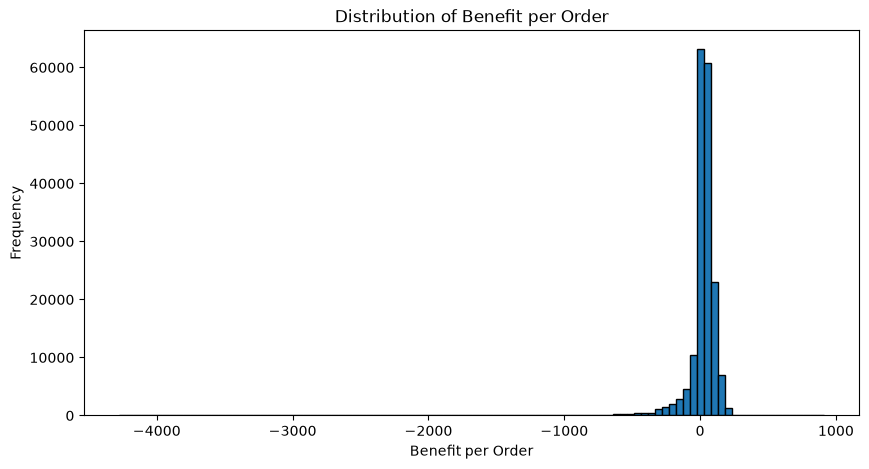

In [27]:
df['Benefit per order'].plot(
    kind='hist',
    bins=100,
    figsize=(10, 5),
    edgecolor='black'
)

plt.title('Distribution of Benefit per Order')
plt.xlabel('Benefit per Order')
plt.show()

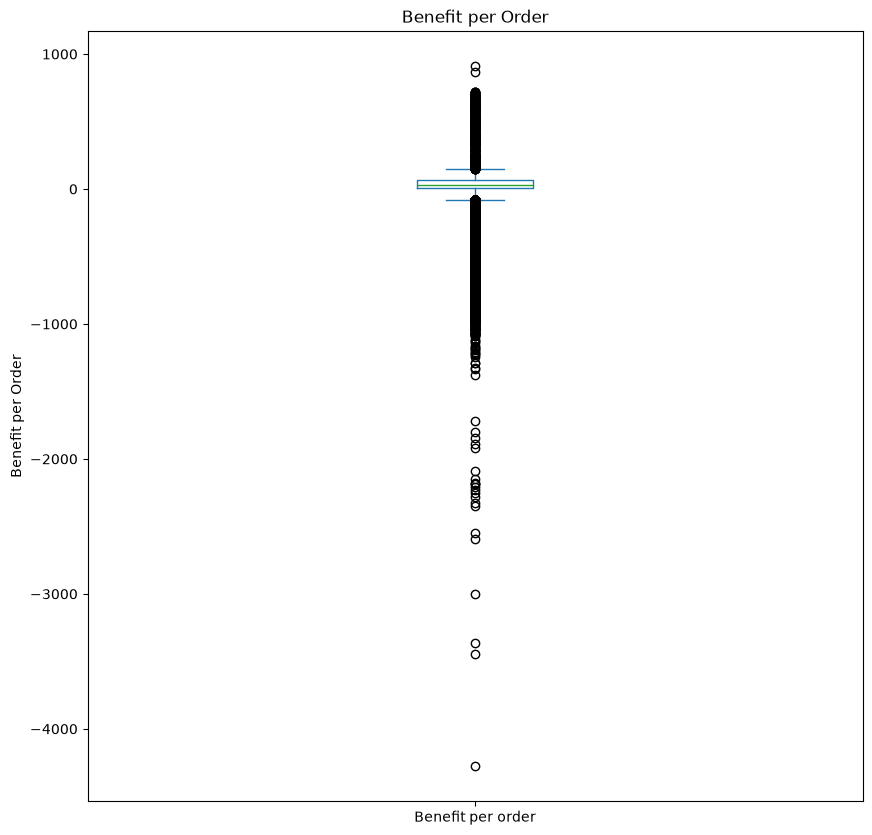

In [28]:
df['Benefit per order'].plot(kind='box', figsize=(10, 10))

plt.title('Benefit per Order')
plt.ylabel('Benefit per Order')
plt.show()

In [29]:
print(df['Benefit per order'].describe())

count    180519.000000
mean         21.974989
std         104.433526
min       -4274.979980
25%           7.000000
50%          31.520000
75%          64.800003
max         911.799988
Name: Benefit per order, dtype: float64


After assesing the values in *Benefit per order*, here is my reasoning:
- The outliers are valid values - benefit per order can be negative.
- The outliers follow the profit formula as well as the rest of the rows.
- All the values in the column can help with analysis questions, therefore they won't be dropped.

### Order Item Profit Ratio

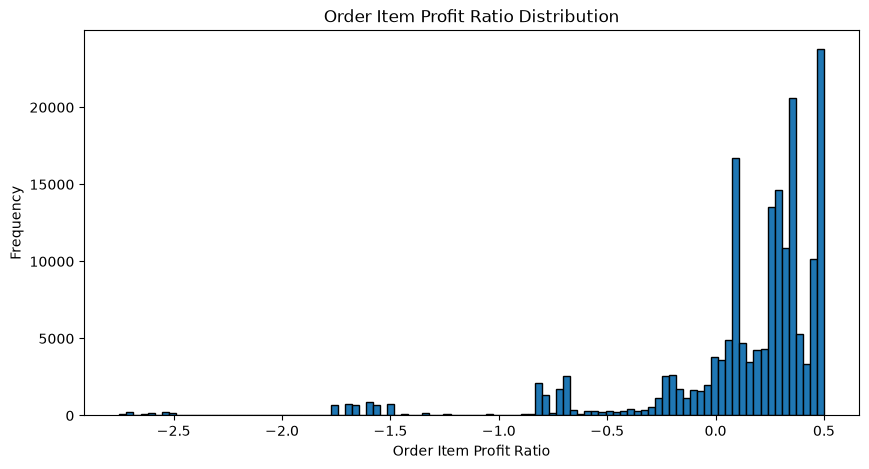

In [30]:
df['Order Item Profit Ratio'].plot(
    kind='hist',
    bins=100,
    figsize=(10, 5),
    edgecolor='black'
)

plt.title('Order Item Profit Ratio Distribution')
plt.xlabel('Order Item Profit Ratio')
plt.show()

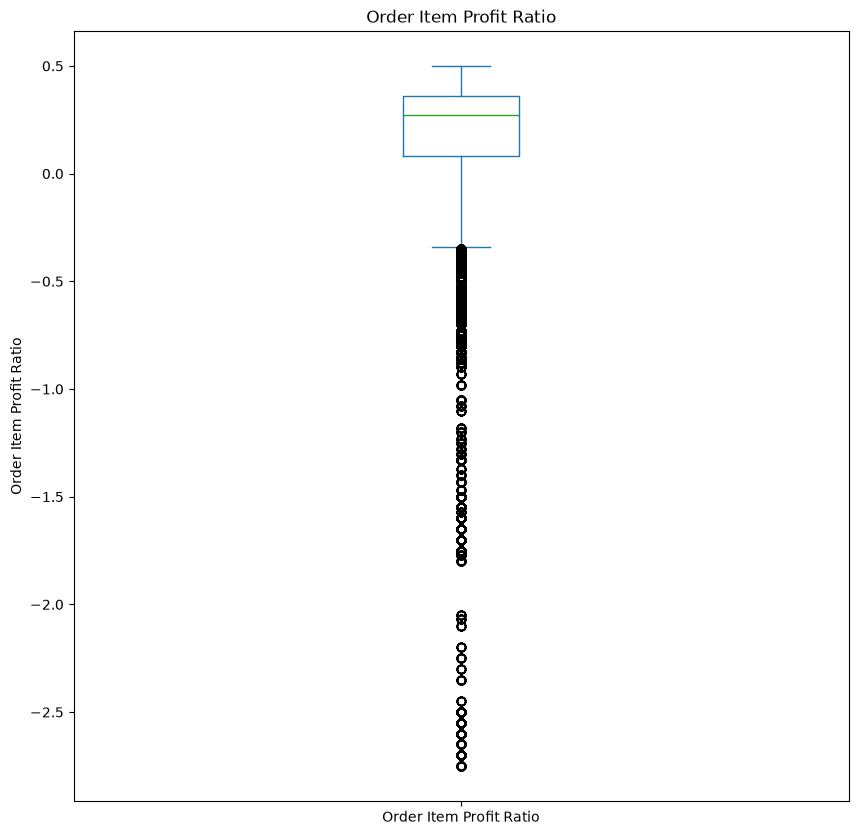

In [31]:
df['Order Item Profit Ratio'].plot(
    kind='box',
    figsize=(10, 10)
)

plt.title('Order Item Profit Ratio')
plt.ylabel('Order Item Profit Ratio')
plt.show()

In [32]:
print(df['Order Item Profit Ratio'].describe())

count    180519.000000
mean          0.120647
std           0.466796
min          -2.750000
25%           0.080000
50%           0.270000
75%           0.360000
max           0.500000
Name: Order Item Profit Ratio, dtype: float64


After assesing the values in *Order Item Profit Ratio*, here is my reasoning:
- The outliers are valid values - order item profit ratio can be negative.
- The outliers follow the profit formula as well as the rest of the rows.
- All the values in the column can help with analysis questions, therefore they won't be dropped.

### Are the Outliers Recorded Consistently?

Profit should equal *Order Item Profit Ratio* × *Order Item Total*. The ratio is rounded to 2 decimals, so a small difference is allowed. If the outliers follow this rule as well as the other rows do, they were recorded consistently and are unlikely to be entry errors.

In [45]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)


profit = df['Order Profit Per Order']
ratio = df['Order Item Profit Ratio']
item_total = df['Order Item Total']

expected_profit = ratio * item_total
consistent = (profit - expected_profit).abs() <= 0.005 * item_total + 0.01

profit_outliers = iqr_outliers(profit)
ratio_outliers = iqr_outliers(ratio)

print(f'Profit = ratio x item total, all rows:     {consistent.mean():.3%}')
print(f'Profit = ratio x item total, profit outliers: {consistent[profit_outliers].mean():.3%}')
print(f'Profit = ratio x item total, ratio outliers:  {consistent[ratio_outliers].mean():.3%}')

Profit = ratio x item total, all rows:     99.998%
Profit = ratio x item total, profit outliers: 99.989%
Profit = ratio x item total, ratio outliers:  99.983%


In [34]:
print(f'Profit outliers: {profit_outliers.sum():,}')
print(f'Ratio outliers: {ratio_outliers.sum():,}')
print(f'Outliers in both: {(profit_outliers & ratio_outliers).sum():,}')
print()
q1, q3 = ratio.quantile([0.25, 0.75])
upper_bound = q3 + 1.5 * (q3 - q1)
print(f'Ratio outliers above the upper bound ({upper_bound:.2f}): {(ratio > upper_bound).sum():,}')
print(f'Rows at the maximum ratio ({ratio.max()}): {(ratio == ratio.max()).sum():,}')
print(f'Rows with ratio below -1 (loss larger than the revenue): {(ratio < -1).sum():,}')

Profit outliers: 18,942
Ratio outliers: 17,300
Outliers in both: 13,053

Ratio outliers above the upper bound (0.78): 0
Rows at the maximum ratio (0.5): 2,529
Rows with ratio below -1 (loss larger than the revenue): 6,301


## Grain

Each row is an order item, and an order has 1–5 items.

In [36]:
print(f'Rows: {df.shape[0]:,}')
print(f'Unique order items: {df["Order Item Id"].nunique():,}')
print(f'Unique orders: {df["Order Id"].nunique():,}')

Rows: 180,519
Unique order items: 180,519
Unique orders: 65,752


In [43]:
items_per_order = df.groupby('Order Id').size()
items_per_order.value_counts().sort_index()

1    19850
2    11447
3    11398
4    11704
5    11353
Name: count, dtype: int64

In [46]:
multi_item = df[df.groupby('Order Id')['Order Id'].transform('size') > 1]

columns_to_check = [
    'Delivery Status', 'Late_delivery_risk', 'Shipping Mode', 'Days for shipping (real)',
    'Days for shipment (scheduled)', 'Order Status', 'Market', 'Order Region', 'Order Country',
    'order date (DateOrders)', 'shipping date (DateOrders)', 'Order Customer Id', 'Customer Segment',
    'Product Name', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order',
]

(
    multi_item.groupby('Order Id')[columns_to_check]
    .nunique()
    .eq(1)
    .mean()
    .sort_values()
    .round(3)
)

Order Profit Per Order           0.000
Order Item Total                 0.000
Sales                            0.016
Product Name                     0.029
Order Item Quantity              0.154
Customer Segment                 1.000
Order Customer Id                1.000
shipping date (DateOrders)       1.000
order date (DateOrders)          1.000
Delivery Status                  1.000
Market                           1.000
Order Status                     1.000
Days for shipment (scheduled)    1.000
Days for shipping (real)         1.000
Shipping Mode                    1.000
Late_delivery_risk               1.000
Order Region                     1.000
Order Country                    1.000
dtype: float64

In [44]:
example_order_id = multi_item['Order Id'].iloc[0]

df.loc[
    df['Order Id'] == example_order_id,
    ['Order Id', 'Order Item Id', 'Product Name', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order'],
]

,Order Id,Order Item Id,Product Name,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order
48,28744,71956,Perfect Fitness Perfect Rip Deck,2,119.980003,115.180000,-30.750000
131619,28744,71958,O'Brien Men's Neoprene Life Vest,1,49.980000,43.480000,13.610000
131620,28744,71955,O'Brien Men's Neoprene Life Vest,1,49.980000,42.480000,20.389999
179805,28744,71957,Field & Stream Sportsman 16 Gun Fire Safe,1,399.980011,347.980011,34.799999


## Cancelled Shipments

In [40]:
pd.crosstab(df['Order Status'], df['Delivery Status'])

Delivery Status,Advance shipping,Late delivery,Shipping canceled,Shipping on time
Order Status,,,,
CANCELED,0,0,3692,0
CLOSED,4809,11109,0,3698
COMPLETE,14136,34199,0,11156
ON_HOLD,2413,5450,0,1941
PAYMENT_REVIEW,420,1082,0,391
PENDING,4857,11712,0,3658
PENDING_PAYMENT,9588,22922,0,7322
PROCESSING,5369,12503,0,4030
SUSPECTED_FRAUD,0,0,4062,0


In [47]:
pd.crosstab(df['Delivery Status'], df['Late_delivery_risk'])

Late_delivery_risk,0,1
Delivery Status,,
Advance shipping,41592,0
Late delivery,0,98977
Shipping canceled,7754,0
Shipping on time,32196,0


## Conclusions

### Columns to drop

- Identical columns: Benefit per order, Sales per customer, Category Id, Customer Id, Order Item Product Price
- 1:1 mapping columns: Order Item Cardprod Id, Product Image
- Empty columns: Product Description
- Constant columns: Customer Email, Customer Password, Product Status
- Mostly missing columns: Order Zipcode
- Columns that don't align with analysis: Customer Zipcode, Customer Street, Latitude, Longitude, Customer Fname, Customer Lname


### Columns to transform data type

- Dates: order date (DateOrders), shipping date (DateOrders)


### Leading/trailing whitespace

- Category Name: 1,475 values
- Department Name: 362 values
- Order Region: 17,925 values
- Product Name: 1,774 values

### Known limitations

- Country and state names are in Spanish
- *Late_delivery_risk* duplicates *Delivery Status* - It equals 1 exactly when Delivery Status == 'Late delivery'.


*tokenized_access_logs.csv* is out of scope because there are no keys to link it to orders.